This notebook is dedicated to running a classifaction model on 1500 simulated CCSN. 
<br>
A model is built using `zams`, `xi_1.5`, `xi_1.75`, `xi_2.0`, `xi_2.25`, `xi_2.5`, `xi_2.75`, `xi_3.0`, `coremass_Si`, `corerad_Si`, `coremass_Fe`, `corerad_Fe` to predict `explosion`
<br>
<br>
*Model Accuracy*
<br>
**DecisionTreeClassifier: 0.979** 
<br>
**RandomForestClassifier: 0.986**

*Main Observations - feature importance is tentative*
1. `Zams` seems important when predicting explosion
2. `silicon_mass` & `silicon_rad` are also important
3. Remove multicollinearity from data to improve feature importance score


*Notes*
1. DecisionTreeClassifier is not considered industry standard - prone to overfitting, but it helps visualize tree diagram.
2. RandomForestClassifer addresses DTC's overfitting. It randomly selects root(p) features to built trees each iteration so as to not have a single feature dominate splitting. After n trees have been produced, the final prediction is obtained by averaging or taking a vote over the predictions of all the trees, leading to improved generalization performance.
3. Since only about 11% of stars do not explode, we will consider stratifing our data. Stratifing the data will be increase representation when sampling. This will reduce sampling bias and increase accuracy.

In [1]:
# import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split

# DecisionTreeClassifier
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

# RandomForestClassifer
from sklearn.ensemble import RandomForestClassifier

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV

In [2]:
# read in the dataset
data = pd.read_csv("results_s18.csv")

In [3]:
# split data into train/test
X = data.drop(columns = ['exploded'])
y = data.exploded
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state = 304)

In [4]:
y_test.value_counts()/len(y_test)

True     0.885333
False    0.114667
Name: exploded, dtype: float64

In [5]:
y_train.value_counts()/len(y_train)

True     0.885333
False    0.114667
Name: exploded, dtype: float64

## DecisionTreeClassifier

In [6]:
# build decision tree
model = DecisionTreeClassifier(max_depth = 5, random_state = 304).fit(X_train, y_train)

In [7]:
# what tree was built?
print(tree.export_text(model, feature_names = list(X.columns)))

|--- max_antesonic <= 0.20
|   |--- class: False
|--- max_antesonic >  0.20
|   |--- xi_2.25 <= 0.04
|   |   |--- class: False
|   |--- xi_2.25 >  0.04
|   |   |--- max_antesonic <= 0.23
|   |   |   |--- xi_3.0 <= 0.05
|   |   |   |   |--- class: False
|   |   |   |--- xi_3.0 >  0.05
|   |   |   |   |--- class: True
|   |   |--- max_antesonic >  0.23
|   |   |   |--- corerad_Si <= 619414176.00
|   |   |   |   |--- class: True
|   |   |   |--- corerad_Si >  619414176.00
|   |   |   |   |--- central_ye <= 0.44
|   |   |   |   |   |--- class: True
|   |   |   |   |--- central_ye >  0.44
|   |   |   |   |   |--- class: False



In [8]:
# score produced
model.score(X_test, y_test)

1.0

In [9]:
# tune hyper parameters
max_depth = range(1,11)
fit_params = {'max_depth': max_depth}
model_cv = GridSearchCV(DecisionTreeClassifier(), fit_params, cv = 10, scoring = 'accuracy', n_jobs = -1)
model_cv.fit(X_train, y_train)
best_model = model_cv.best_estimator_

In [10]:
model_cv.best_params_

{'max_depth': 7}

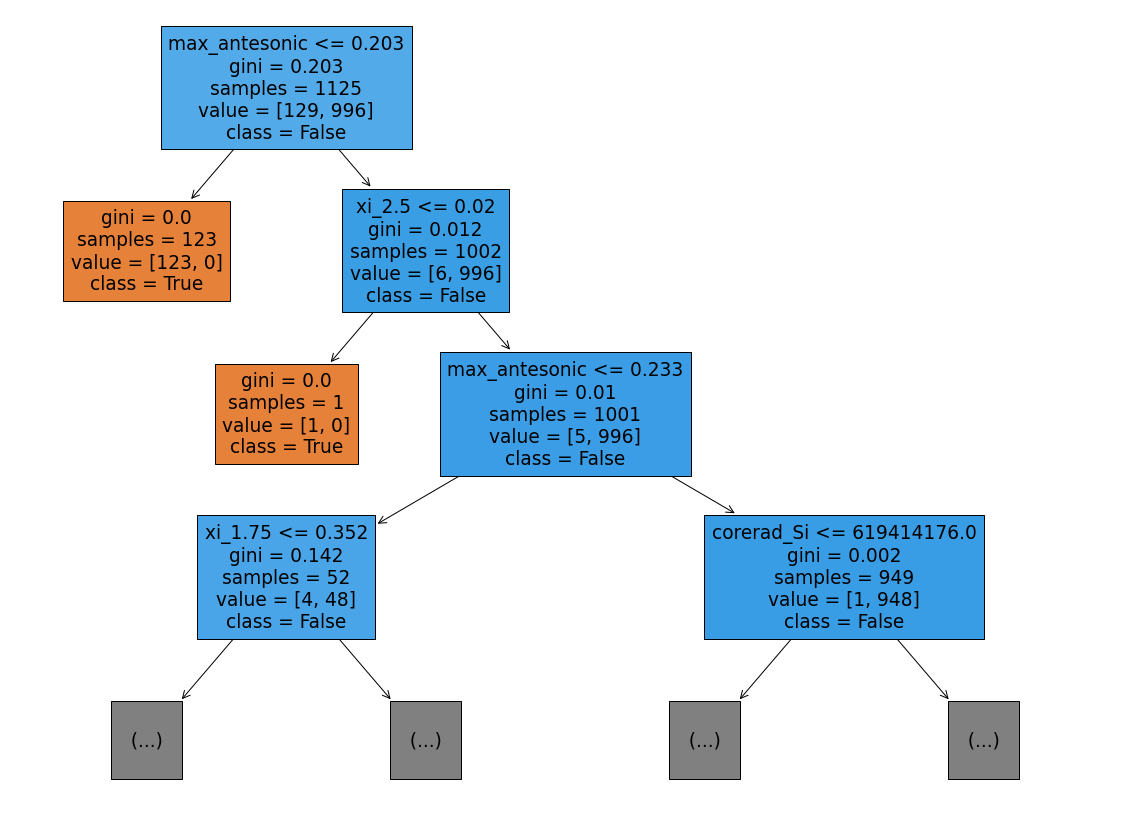

In [11]:
# visualize tree
plt.figure(figsize=(20,15))
tree.plot_tree(best_model,
              feature_names=list(X.columns),
              class_names=["True", "False"],
              filled = True,
              max_depth=3)
plt.show()

## RandomForestClassifier

In [12]:
# build model
model = RandomForestClassifier(random_state = 0, n_estimators = 50).fit(X_train, y_train)
model.score(X_test, y_test)

0.9973333333333333

In [13]:
# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 500, 1000],  
    'max_features': ['sqrt', 'log2', None],
    'max_depth': [None, 3, 5, 10],
    'criterion': ['gini',] #'entropy']
}

# Create RandomForestClassifier
rf_model = RandomForestClassifier(random_state=6)

# Create GridSearchCV object
cv_model = GridSearchCV(rf_model, param_grid, scoring='accuracy', cv=10, n_jobs=-1)

# Fit the model on training data
cv_model.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=6), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [None, 3, 5, 10],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [100, 500, 1000]},
             scoring='accuracy')

In [14]:
best_model = cv_model.best_estimator_
best_model.score(X_test, y_test)
cv_model.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'n_estimators': 100}

In [15]:
## extract one bootstrapped tree
# fn=list(X.columns)
# cn=['True', 'False']
# fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=800)
# tree.plot_tree(best_model.estimators_[1],
#                feature_names = fn, 
#                class_names=cn,
#                filled = True);

### Feature importance

for more information on plots:
<br>
https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

**Note:** Using Model that was NOT cross validated

In [16]:
import time

import numpy as np

feature_names = list(X.columns)
start_time = time.time()
importances = model.feature_importances_
std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.005 seconds


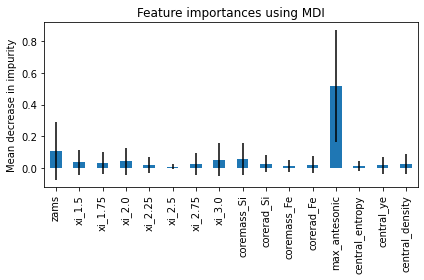

In [17]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [18]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 2.301 seconds


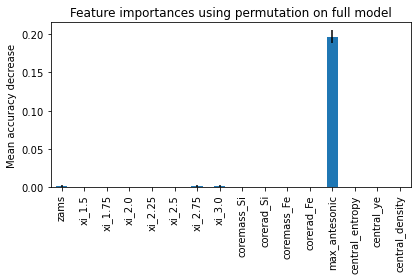

In [19]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

# Trying the same model on the 200 data points dataset

In [20]:
# read in the dataset
data = pd.read_csv("results_s16.csv")

In [21]:
# split data into train/test
X = data.drop(columns = ['exploded'])
y = data.exploded
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state = 304)

In [22]:
y_test.value_counts()/len(y_test)

True     0.76
False    0.24
Name: exploded, dtype: float64

In [23]:
y_train.value_counts()/len(y_train)

True     0.746667
False    0.253333
Name: exploded, dtype: float64

## DecisionTreeClassifier

In [24]:
# build decision tree
model = DecisionTreeClassifier(max_depth = 5, random_state = 304).fit(X_train, y_train)

In [25]:
# what tree was built?
print(tree.export_text(model, feature_names = list(X.columns)))

|--- max_antesonic <= 0.22
|   |--- class: False
|--- max_antesonic >  0.22
|   |--- class: True



In [26]:
# score produced
model.score(X_test, y_test)

1.0

In [27]:
# tune hyper parameters
max_depth = range(1,11)
fit_params = {'max_depth': max_depth}
model_cv = GridSearchCV(DecisionTreeClassifier(), fit_params, cv = 10, scoring = 'accuracy', n_jobs = -1)
model_cv.fit(X_train, y_train)
best_model = model_cv.best_estimator_

In [28]:
model_cv.best_params_

{'max_depth': 1}

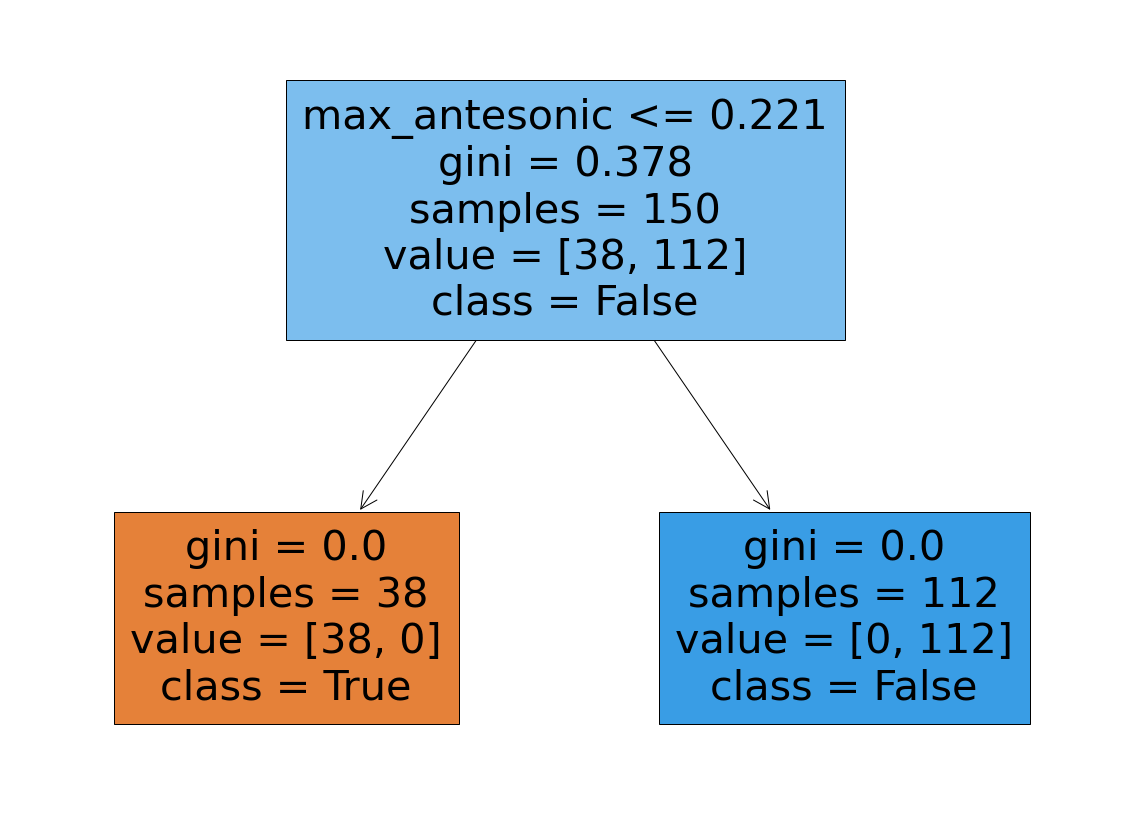

In [29]:
# visualize tree
plt.figure(figsize=(20,15))
tree.plot_tree(best_model,
              feature_names=list(X.columns),
              class_names=["True", "False"],
              filled = True,
              max_depth=3)
plt.show()

## RandomForestClassifier

In [30]:
# build model
model = RandomForestClassifier(random_state = 0, n_estimators = 50).fit(X_train, y_train)
model.score(X_test, y_test)

1.0

In [31]:
# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 500, 1000],  
    'max_features': ['sqrt', 'log2', None],
    'max_depth': [None, 3, 5, 10],
    'criterion': ['gini',] #'entropy']
}

# Create RandomForestClassifier
rf_model = RandomForestClassifier(random_state=6)

# Create GridSearchCV object
cv_model = GridSearchCV(rf_model, param_grid, scoring='accuracy', cv=10, n_jobs=-1)

# Fit the model on training data
cv_model.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=6), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [None, 3, 5, 10],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [100, 500, 1000]},
             scoring='accuracy')

In [32]:
best_model = cv_model.best_estimator_
best_model.score(X_test, y_test)
cv_model.best_params_

{'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'n_estimators': 100}

In [33]:
## extract one bootstrapped tree
# fn=list(X.columns)
# cn=['True', 'False']
# fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=800)
# tree.plot_tree(best_model.estimators_[1],
#                feature_names = fn, 
#                class_names=cn,
#                filled = True);

### Feature importance

for more information on plots:
<br>
https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

**Note:** Using Model that was NOT cross validated

In [34]:
import time

import numpy as np

feature_names = list(X.columns)
start_time = time.time()
importances = model.feature_importances_
std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.005 seconds


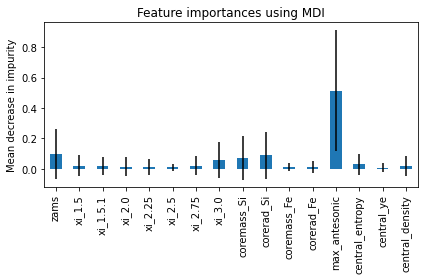

In [35]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [36]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 2.538 seconds


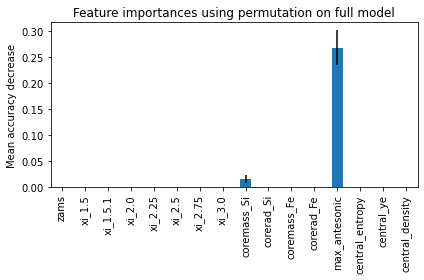

In [37]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

# Trying out without max_antesonic

In [38]:
# read in the dataset
data = pd.read_csv("results_s16.csv")

In [39]:
data = data.drop(['max_antesonic'], axis = 1)

In [40]:
# split data into train/test
X = data.drop(columns = ['exploded'])
y = data.exploded
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state = 304)

In [41]:
y_test.value_counts()/len(y_test)

True     0.76
False    0.24
Name: exploded, dtype: float64

In [42]:
y_train.value_counts()/len(y_train)

True     0.746667
False    0.253333
Name: exploded, dtype: float64

## DecisionTreeClassifier

In [43]:
# build decision tree
model = DecisionTreeClassifier(max_depth = 5, random_state = 304).fit(X_train, y_train)

In [44]:
# what tree was built?
print(tree.export_text(model, feature_names = list(X.columns)))

|--- zams <= 15.65
|   |--- coremass_Si <= 1.52
|   |   |--- class: True
|   |--- coremass_Si >  1.52
|   |   |--- class: False
|--- zams >  15.65
|   |--- corerad_Si <= 431484224.00
|   |   |--- zams <= 18.45
|   |   |   |--- corerad_Fe <= 143253320.00
|   |   |   |   |--- class: True
|   |   |   |--- corerad_Fe >  143253320.00
|   |   |   |   |--- class: False
|   |   |--- zams >  18.45
|   |   |   |--- class: True
|   |--- corerad_Si >  431484224.00
|   |   |--- zams <= 27.80
|   |   |   |--- xi_2.0 <= 0.24
|   |   |   |   |--- xi_1.5 <= 0.77
|   |   |   |   |   |--- class: False
|   |   |   |   |--- xi_1.5 >  0.77
|   |   |   |   |   |--- class: True
|   |   |   |--- xi_2.0 >  0.24
|   |   |   |   |--- class: False
|   |   |--- zams >  27.80
|   |   |   |--- xi_3.0 <= 0.21
|   |   |   |   |--- class: True
|   |   |   |--- xi_3.0 >  0.21
|   |   |   |   |--- class: False



In [45]:
# score produced
model.score(X_test, y_test)

0.92

In [46]:
# tune hyper parameters
max_depth = range(1,11)
fit_params = {'max_depth': max_depth}
model_cv = GridSearchCV(DecisionTreeClassifier(), fit_params, cv = 10, scoring = 'accuracy', n_jobs = -1)
model_cv.fit(X_train, y_train)
best_model = model_cv.best_estimator_

In [47]:
model_cv.best_params_

{'max_depth': 6}

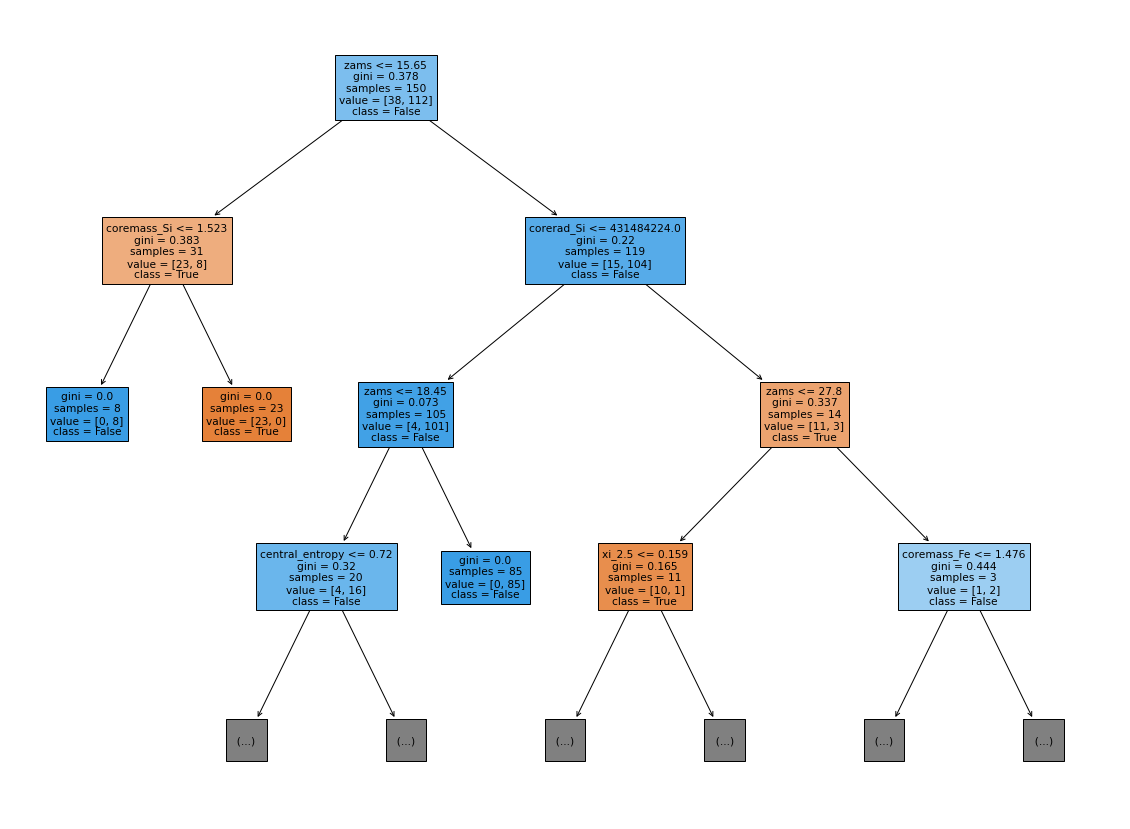

In [48]:
# visualize tree
plt.figure(figsize=(20,15))
tree.plot_tree(best_model,
              feature_names=list(X.columns),
              class_names=["True", "False"],
              filled = True,
              max_depth=3)
plt.show()

## RandomForestClassifier

In [49]:
# build model
model = RandomForestClassifier(random_state = 0, n_estimators = 50).fit(X_train, y_train)
model.score(X_test, y_test)

0.92

In [50]:
# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 500, 1000],  
    'max_features': ['sqrt', 'log2', None],
    'max_depth': [None, 3, 5, 10],
    'criterion': ['gini',] #'entropy']
}

# Create RandomForestClassifier
rf_model = RandomForestClassifier(random_state=6)

# Create GridSearchCV object
cv_model = GridSearchCV(rf_model, param_grid, scoring='accuracy', cv=10, n_jobs=-1)

# Fit the model on training data
cv_model.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=6), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [None, 3, 5, 10],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [100, 500, 1000]},
             scoring='accuracy')

In [51]:
best_model = cv_model.best_estimator_
print(best_model.score(X_test, y_test))
cv_model.best_params_

0.92


{'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'n_estimators': 500}

In [52]:
## extract one bootstrapped tree
# fn=list(X.columns)
# cn=['True', 'False']
# fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=800)
# tree.plot_tree(best_model.estimators_[1],
#                feature_names = fn, 
#                class_names=cn,
#                filled = True);

### Feature importance

for more information on plots:
<br>
https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

**Note:** Using Model that was NOT cross validated

In [53]:
import time

import numpy as np

feature_names = list(X.columns)
start_time = time.time()
importances = model.feature_importances_
std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.004 seconds


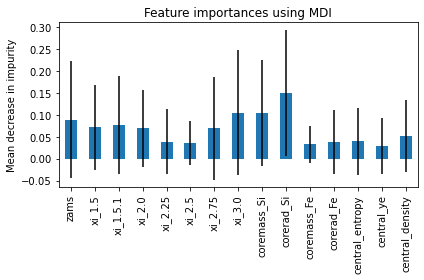

In [54]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [55]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 4.385 seconds


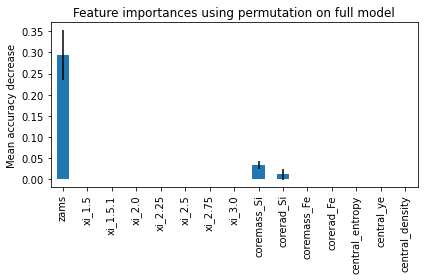

In [56]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

# Calculating Variance Inflation Factor to check for multi_colinearity

To find multicollinearity among the xi values, we'll calculate the Variance Inflation Factor (VIF) for each xi feature. Multicollinearity exists when one predictor variable in a multiple regression model can be linearly predicted from the others with a substantial degree of accuracy. A common threshold for concern with VIF is 5 or above.



In [57]:
data = data.drop(['xi_1.5.1'], axis = 1)

In [58]:
data.head()

,zams,xi_1.5,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,central_entropy,central_ye,central_density
0,9.00,0.005255,0.000047,0.000041,0.000038,0.000037,0.000036,1.319596,1.385851e+08,1.319596,1.385851e+08,True,0.532258,0.430050,1.634080e+10
1,9.25,0.028243,0.000075,0.000054,0.000047,0.000044,0.000042,1.343052,1.469831e+08,1.290904,1.067884e+08,True,0.540415,0.428927,1.869078e+10
2,9.50,0.093333,0.002250,0.000091,0.000062,0.000053,0.000048,1.357887,1.519480e+08,1.302871,1.088876e+08,True,0.540496,0.430310,1.777634e+10
3,9.75,0.304821,0.005737,0.002271,0.000104,0.000067,0.000056,1.396045,1.832699e+08,1.300979,1.090382e+08,True,0.542151,0.432666,1.469587e+10
4,10.00,0.454843,0.007223,0.003974,0.000216,0.000066,0.000051,1.415957,1.644623e+08,1.343002,1.193591e+08,True,0.558971,0.432718,1.504105e+10


In [59]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Selecting only the xi columns
xi_columns = [col for col in data.columns if 'xi_' in col]
xi_data = data[xi_columns]

# Calculating VIF
vif_data = pd.DataFrame()
vif_data["feature"] = xi_data.columns
vif_data["VIF"] = [variance_inflation_factor(xi_data.values, i) for i in range(len(xi_data.columns))]

vif_data

,feature,VIF
0,xi_1.5,9.031938
1,xi_2.0,476.865914
2,xi_2.25,3890.148198
3,xi_2.5,11614.421516
4,xi_2.75,11611.325288
5,xi_3.0,2075.093825


**Check VIF for core_masses/core_rads**

Feature list to try: xi_3.0, xi_coreSi, xi_coreFe

Consider reducing/combining some of these xi values to reduce redundancy and improve model

In [60]:
data

,zams,xi_1.5,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,central_entropy,central_ye,central_density
0,9.00,0.005255,0.000047,0.000041,0.000038,0.000037,0.000036,1.319596,1.385851e+08,1.319596,1.385851e+08,True,0.532258,0.430050,1.634080e+10
1,9.25,0.028243,0.000075,0.000054,0.000047,0.000044,0.000042,1.343052,1.469831e+08,1.290904,1.067884e+08,True,0.540415,0.428927,1.869078e+10
2,9.50,0.093333,0.002250,0.000091,0.000062,0.000053,0.000048,1.357887,1.519480e+08,1.302871,1.088876e+08,True,0.540496,0.430310,1.777634e+10
3,9.75,0.304821,0.005737,0.002271,0.000104,0.000067,0.000056,1.396045,1.832699e+08,1.300979,1.090382e+08,True,0.542151,0.432666,1.469587e+10
4,10.00,0.454843,0.007223,0.003974,0.000216,0.000066,0.000051,1.415957,1.644623e+08,1.343002,1.193591e+08,True,0.558971,0.432718,1.504105e+10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,60.00,0.929947,0.281143,0.217657,0.174576,0.152117,0.138267,1.587106,2.027432e+08,1.457770,1.470957e+08,True,0.720532,0.438735,5.774630e+09
196,70.00,0.988711,0.383370,0.287605,0.232572,0.200958,0.180592,1.719733,2.360583e+08,1.503255,1.525284e+08,True,0.804178,0.441520,4.289866e+09
197,80.00,0.960779,0.335015,0.253111,0.208687,0.183372,0.166606,1.658498,2.232799e+08,1.482070,1.509100e+08,True,0.761454,0.440228,4.895937e+09
198,100.00,0.983314,0.452640,0.308111,0.245183,0.210691,0.188312,1.801763,2.797782e+08,1.538623,1.639150e+08,True,0.802600,0.441140,4.732160e+09


# Run an SVM to Find a Decision Boundary

Next, let's run a Support Vector Machine (SVM) model to find a decision boundary between the exploded and non-exploded stars.

In [61]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Preparing the data for SVM
X = data.drop(columns=['exploded'])
y = data['exploded']

# Splitting the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=304)

# Standardizing the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initializing and training the SVM model
svm_model = SVC(kernel='linear', random_state=304)
svm_model.fit(X_train_scaled, y_train)

# Predictions and Evaluation
y_pred = svm_model.predict(X_test_scaled)

# Displaying classification report and confusion matrix
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

       False       0.89      0.67      0.76        12
        True       0.90      0.97      0.94        38

    accuracy                           0.90        50
   macro avg       0.90      0.82      0.85        50
weighted avg       0.90      0.90      0.89        50

[[ 8  4]
 [ 1 37]]


- 8 true negatives (correctly predicted non-exploded),
- 37 true positives (correctly predicted exploded),
- 4 false positives (non-exploded predicted as exploded),
- 1 false negative (exploded predicted as non-exploded).

**Precision** answers the question: "Of all the instances the model labeled as positive, how many are actually positive?"

**Recall** answers the question: "Of all the actual positives in the data, how many did the model successfully identify?"

**F1-score** is a harmonic mean of precision and recall, taking both false positives and false negatives into account. It is a better measure than accuracy for imbalanced datasets. The F1-score reaches its best value at 1 (perfect precision and recall) and worst at 0.

**Support** is the number of actual occurrences of the class in the specified dataset. For each class, it shows how many instances of the class were present in the dataset used for evaluation. It provides a sense of the dataset's class balance or imbalance.



# Finding Feature Importance with a Random Forest Classifier

In [62]:
# Initializing and training the Random Forest model
rf_model = RandomForestClassifier(random_state=304, n_estimators=100)
rf_model.fit(X_train, y_train)

# Extracting feature importance
feature_importances = rf_model.feature_importances_

# Creating a DataFrame to display feature importance
features_df = pd.DataFrame({'Feature': X.columns, 'Importance': feature_importances}).sort_values(by='Importance', ascending=False)

features_df


,Feature,Importance
7,coremass_Si,0.155833
0,zams,0.151418
8,corerad_Si,0.132672
1,xi_1.5,0.082319
11,central_entropy,0.071498
6,xi_3.0,0.071459
5,xi_2.75,0.060595
2,xi_2.0,0.054181
3,xi_2.25,0.042782
13,central_density,0.041362


# Trying permutation after model refinement

In [63]:
feature_names = feature_names[:2]+feature_names[3:]

In [64]:
start_time = time.time()
result = permutation_importance(
    rf_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 0.767 seconds


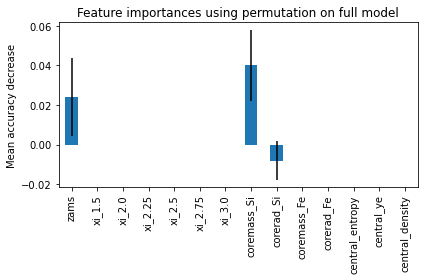

In [65]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

 # Interactions between features

Especially given the multicollinearity among the xi values, it might be insightful to create features that represent interactions between different xi values or between xi values and core properties.


# Trying to Reduce the Number of Features

In [119]:
s16 = pd.read_csv('results_s16.csv').drop(columns=['xi_1.5.1'])
s16.head()

,zams,xi_1.5,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,max_antesonic,central_entropy,central_ye,central_density
0,9.00,0.005255,0.000047,0.000041,0.000038,0.000037,0.000036,1.319596,1.385851e+08,1.319596,1.385851e+08,True,0.321156,0.532258,0.430050,1.634080e+10
1,9.25,0.028243,0.000075,0.000054,0.000047,0.000044,0.000042,1.343052,1.469831e+08,1.290904,1.067884e+08,True,0.357262,0.540415,0.428927,1.869078e+10
2,9.50,0.093333,0.002250,0.000091,0.000062,0.000053,0.000048,1.357887,1.519480e+08,1.302871,1.088876e+08,True,0.362845,0.540496,0.430310,1.777634e+10
3,9.75,0.304821,0.005737,0.002271,0.000104,0.000067,0.000056,1.396045,1.832699e+08,1.300979,1.090382e+08,True,0.395757,0.542151,0.432666,1.469587e+10
4,10.00,0.454843,0.007223,0.003974,0.000216,0.000066,0.000051,1.415957,1.644623e+08,1.343002,1.193591e+08,True,0.406790,0.558971,0.432718,1.504105e+10


In [120]:
corr = s16.corr()
corr.style.background_gradient(cmap='coolwarm')

,zams,xi_1.5,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,max_antesonic,central_entropy,central_ye,central_density
zams,1.000000,0.380586,0.334280,0.349560,0.368277,0.387739,0.406236,0.268603,0.028823,0.304498,0.270558,0.298737,0.386851,0.351485,0.377927,-0.402782
xi_1.5,0.380586,1.000000,0.708072,0.697918,0.696956,0.690783,0.686670,0.566302,0.056817,0.652658,0.559199,0.118405,0.344175,0.720744,0.793299,-0.927382
xi_2.0,0.334280,0.708072,1.000000,0.990310,0.975047,0.954379,0.929782,0.876211,0.173942,0.936908,0.792336,0.242933,0.502935,0.972804,0.914086,-0.825898
xi_2.25,0.349560,0.697918,0.990310,1.000000,0.994240,0.979688,0.958590,0.879048,0.196044,0.925396,0.775930,0.290930,0.544276,0.965530,0.902671,-0.821391
xi_2.5,0.368277,0.696956,0.975047,0.994240,1.000000,0.994734,0.980538,0.867960,0.206524,0.904094,0.751144,0.338781,0.582421,0.952796,0.892257,-0.819289
xi_2.75,0.387739,0.690783,0.954379,0.979688,0.994734,1.000000,0.994867,0.849949,0.208097,0.878424,0.717573,0.389649,0.621288,0.937279,0.881831,-0.809030
xi_3.0,0.406236,0.686670,0.929782,0.958590,0.980538,0.994867,1.000000,0.824130,0.196133,0.851807,0.682014,0.436478,0.655471,0.922448,0.877330,-0.800373
coremass_Si,0.268603,0.566302,0.876211,0.879048,0.867960,0.849949,0.824130,1.000000,0.598345,0.809287,0.689401,-0.000204,0.252838,0.804420,0.734743,-0.645756
corerad_Si,0.028823,0.056817,0.173942,0.196044,0.206524,0.208097,0.196133,0.598345,1.000000,0.058884,0.047051,-0.383461,-0.269973,0.036703,-0.019944,-0.019536
coremass_Fe,0.304498,0.652658,0.936908,0.925396,0.904094,0.878424,0.851807,0.809287,0.058884,1.000000,0.925646,0.209074,0.440616,0.942870,0.893252,-0.786451


In [121]:
corr = s16.iloc[:,1:7].corr()
corr.style.background_gradient(cmap='coolwarm')

,xi_1.5,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0
xi_1.5,1.000000,0.708072,0.697918,0.696956,0.690783,0.686670
xi_2.0,0.708072,1.000000,0.990310,0.975047,0.954379,0.929782
xi_2.25,0.697918,0.990310,1.000000,0.994240,0.979688,0.958590
xi_2.5,0.696956,0.975047,0.994240,1.000000,0.994734,0.980538
xi_2.75,0.690783,0.954379,0.979688,0.994734,1.000000,0.994867
xi_3.0,0.686670,0.929782,0.958590,0.980538,0.994867,1.000000


### So, since xi_1.5 has the most vital and uncorrelated information, we will keep only xi_1.5 out of all the xi's.

In [122]:
red_s16 = s16.drop(columns=['xi_2.0', 'xi_2.25', 'xi_2.5', 'xi_2.75', 'xi_3.0'])
corr = red_s16.corr()
corr.style.background_gradient(cmap='coolwarm')

,zams,xi_1.5,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded,max_antesonic,central_entropy,central_ye,central_density
zams,1.000000,0.380586,0.268603,0.028823,0.304498,0.270558,0.298737,0.386851,0.351485,0.377927,-0.402782
xi_1.5,0.380586,1.000000,0.566302,0.056817,0.652658,0.559199,0.118405,0.344175,0.720744,0.793299,-0.927382
coremass_Si,0.268603,0.566302,1.000000,0.598345,0.809287,0.689401,-0.000204,0.252838,0.804420,0.734743,-0.645756
corerad_Si,0.028823,0.056817,0.598345,1.000000,0.058884,0.047051,-0.383461,-0.269973,0.036703,-0.019944,-0.019536
coremass_Fe,0.304498,0.652658,0.809287,0.058884,1.000000,0.925646,0.209074,0.440616,0.942870,0.893252,-0.786451
corerad_Fe,0.270558,0.559199,0.689401,0.047051,0.925646,1.000000,0.047265,0.253265,0.788528,0.743993,-0.720887
exploded,0.298737,0.118405,-0.000204,-0.383461,0.209074,0.047265,1.000000,0.945514,0.333638,0.311484,-0.191607
max_antesonic,0.386851,0.344175,0.252838,-0.269973,0.440616,0.253265,0.945514,1.000000,0.570256,0.534433,-0.429675
central_entropy,0.351485,0.720744,0.804420,0.036703,0.942870,0.788528,0.333638,0.570256,1.000000,0.969327,-0.856729
central_ye,0.377927,0.793299,0.734743,-0.019944,0.893252,0.743993,0.311484,0.534433,0.969327,1.000000,-0.907538


### Now, coremass_Fe and corerad_Fe are very correlated but corerad_Fe is less correlated with other features so we can keep that. 

In [123]:
data16 = red_s16.drop(columns=['coremass_Fe'])
corr = data16.corr()
corr.style.background_gradient(cmap='coolwarm')

,zams,xi_1.5,coremass_Si,corerad_Si,corerad_Fe,exploded,max_antesonic,central_entropy,central_ye,central_density
zams,1.000000,0.380586,0.268603,0.028823,0.270558,0.298737,0.386851,0.351485,0.377927,-0.402782
xi_1.5,0.380586,1.000000,0.566302,0.056817,0.559199,0.118405,0.344175,0.720744,0.793299,-0.927382
coremass_Si,0.268603,0.566302,1.000000,0.598345,0.689401,-0.000204,0.252838,0.804420,0.734743,-0.645756
corerad_Si,0.028823,0.056817,0.598345,1.000000,0.047051,-0.383461,-0.269973,0.036703,-0.019944,-0.019536
corerad_Fe,0.270558,0.559199,0.689401,0.047051,1.000000,0.047265,0.253265,0.788528,0.743993,-0.720887
exploded,0.298737,0.118405,-0.000204,-0.383461,0.047265,1.000000,0.945514,0.333638,0.311484,-0.191607
max_antesonic,0.386851,0.344175,0.252838,-0.269973,0.253265,0.945514,1.000000,0.570256,0.534433,-0.429675
central_entropy,0.351485,0.720744,0.804420,0.036703,0.788528,0.333638,0.570256,1.000000,0.969327,-0.856729
central_ye,0.377927,0.793299,0.734743,-0.019944,0.743993,0.311484,0.534433,0.969327,1.000000,-0.907538
central_density,-0.402782,-0.927382,-0.645756,-0.019536,-0.720887,-0.191607,-0.429675,-0.856729,-0.907538,1.000000


**Now, this looks like an uncorrelated final dataset we can work on.**

In [124]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Selecting only the xi columns
columns_ = [col for col in data16.columns if 'exploded' not in col]
data = data16[columns_]

# Calculating VIF
vif_data = pd.DataFrame()
vif_data["feature"] = data.columns
vif_data["VIF"] = [variance_inflation_factor(data.values, i) for i in range(len(data.columns))]

vif_data

,feature,VIF
0,zams,5.753012
1,xi_1.5,358.544216
2,coremass_Si,6225.375276
3,corerad_Si,172.694460
4,corerad_Fe,266.706645
5,max_antesonic,21.308278
6,central_entropy,3227.237426
7,central_ye,1394.667349
8,central_density,143.493992


# Working with DTC now:

In [125]:
data = data.drop(['max_antesonic'], axis = 1)

In [126]:
data['exploded'] = s16['exploded']

In [127]:
# split data into train/test
X = data.drop(columns = ['exploded'])
y = data.exploded
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state = 304)

In [128]:
y_test.value_counts()/len(y_test)

True     0.76
False    0.24
Name: exploded, dtype: float64

In [129]:
data

,zams,xi_1.5,coremass_Si,corerad_Si,corerad_Fe,central_entropy,central_ye,central_density,exploded
0,9.00,0.005255,1.319596,1.385851e+08,1.385851e+08,0.532258,0.430050,1.634080e+10,True
1,9.25,0.028243,1.343052,1.469831e+08,1.067884e+08,0.540415,0.428927,1.869078e+10,True
2,9.50,0.093333,1.357887,1.519480e+08,1.088876e+08,0.540496,0.430310,1.777634e+10,True
3,9.75,0.304821,1.396045,1.832699e+08,1.090382e+08,0.542151,0.432666,1.469587e+10,True
4,10.00,0.454843,1.415957,1.644623e+08,1.193591e+08,0.558971,0.432718,1.504105e+10,True
...,...,...,...,...,...,...,...,...,...
195,60.00,0.929947,1.587106,2.027432e+08,1.470957e+08,0.720532,0.438735,5.774630e+09,True
196,70.00,0.988711,1.719733,2.360583e+08,1.525284e+08,0.804178,0.441520,4.289866e+09,True
197,80.00,0.960779,1.658498,2.232799e+08,1.509100e+08,0.761454,0.440228,4.895937e+09,True
198,100.00,0.983314,1.801763,2.797782e+08,1.639150e+08,0.802600,0.441140,4.732160e+09,True


In [130]:
y_train.value_counts()/len(y_train)

True     0.746667
False    0.253333
Name: exploded, dtype: float64

## DecisionTreeClassifier

In [131]:
# build decision tree
model = DecisionTreeClassifier(max_depth = 5, random_state = 304).fit(X_train, y_train)

In [132]:
# what tree was built?
print(tree.export_text(model, feature_names = list(X.columns)))

|--- zams <= 15.65
|   |--- coremass_Si <= 1.52
|   |   |--- class: True
|   |--- coremass_Si >  1.52
|   |   |--- class: False
|--- zams >  15.65
|   |--- corerad_Si <= 431484224.00
|   |   |--- zams <= 18.45
|   |   |   |--- corerad_Fe <= 143253320.00
|   |   |   |   |--- class: True
|   |   |   |--- corerad_Fe >  143253320.00
|   |   |   |   |--- class: False
|   |   |--- zams >  18.45
|   |   |   |--- class: True
|   |--- corerad_Si >  431484224.00
|   |   |--- zams <= 27.80
|   |   |   |--- central_ye <= 0.43
|   |   |   |   |--- central_density <= 8523244288.00
|   |   |   |   |   |--- class: True
|   |   |   |   |--- central_density >  8523244288.00
|   |   |   |   |   |--- class: False
|   |   |   |--- central_ye >  0.43
|   |   |   |   |--- class: False
|   |   |--- zams >  27.80
|   |   |   |--- central_density <= 6066896384.00
|   |   |   |   |--- class: False
|   |   |   |--- central_density >  6066896384.00
|   |   |   |   |--- class: True



In [133]:
# score produced
model.score(X_test, y_test)

0.92

In [134]:
# tune hyper parameters
max_depth = range(1,11)
fit_params = {'max_depth': max_depth}
model_cv = GridSearchCV(DecisionTreeClassifier(), fit_params, cv = 10, scoring = 'accuracy', n_jobs = -1)
model_cv.fit(X_train, y_train)
best_model = model_cv.best_estimator_

In [135]:
model_cv.best_params_

{'max_depth': 4}

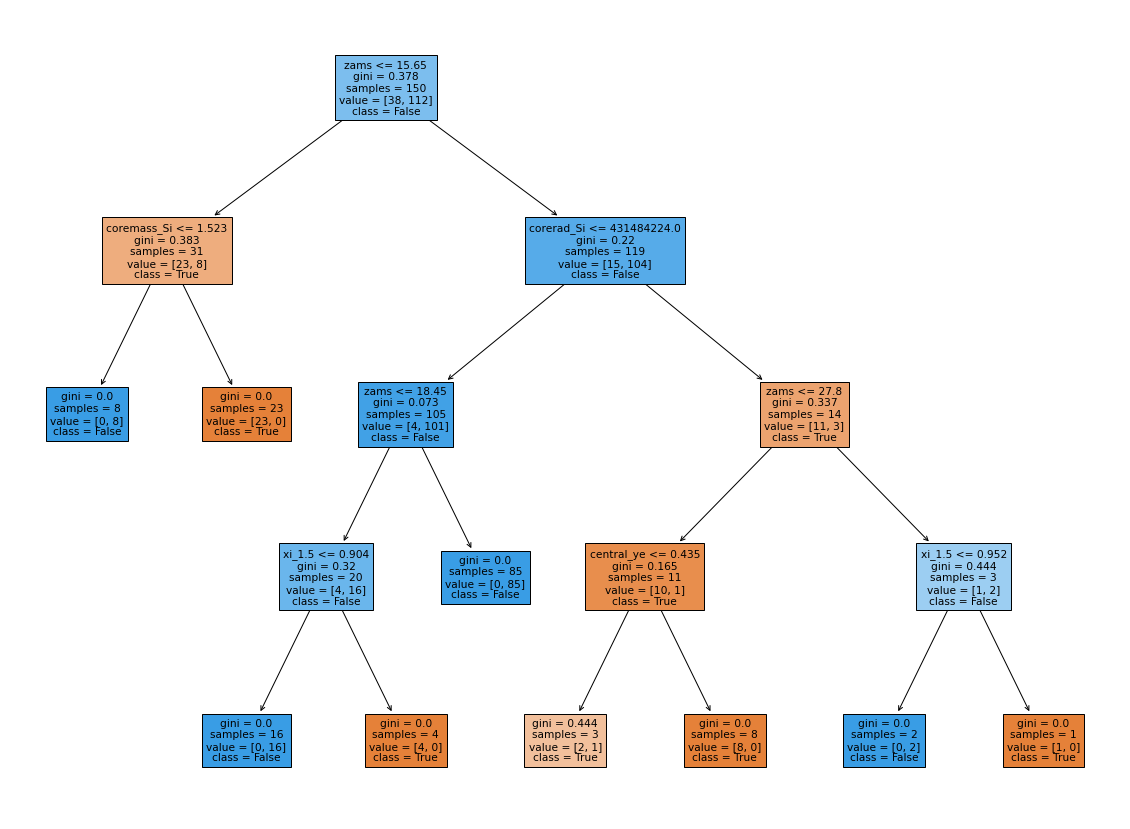

In [136]:
# visualize tree
plt.figure(figsize=(20,15))
tree.plot_tree(best_model,
              feature_names=list(X.columns),
              class_names=["True", "False"],
              filled = True,
              max_depth=4)
plt.show()

## RandomForestClassifier

In [84]:
# build model
model = RandomForestClassifier(random_state = 0, n_estimators = 50).fit(X_train, y_train)
model.score(X_test, y_test)

0.92

In [85]:
# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 500, 1000],  
    'max_features': ['sqrt', 'log2', None],
    'max_depth': [None, 3, 5, 10],
    'criterion': ['gini',] #'entropy']
}

# Create RandomForestClassifier
rf_model = RandomForestClassifier(random_state=6)

# Create GridSearchCV object
cv_model = GridSearchCV(rf_model, param_grid, scoring='accuracy', cv=10, n_jobs=-1)

# Fit the model on training data
cv_model.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=6), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [None, 3, 5, 10],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [100, 500, 1000]},
             scoring='accuracy')

In [86]:
best_model = cv_model.best_estimator_
print(best_model.score(X_test, y_test))
cv_model.best_params_

0.92


{'criterion': 'gini',
 'max_depth': None,
 'max_features': 'log2',
 'n_estimators': 100}

### Feature importance

for more information on plots:
<br>
https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

**Note:** Using Model that was NOT cross validated

In [87]:
import time

import numpy as np

feature_names = list(X.columns)
start_time = time.time()
importances = model.feature_importances_
std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.010 seconds


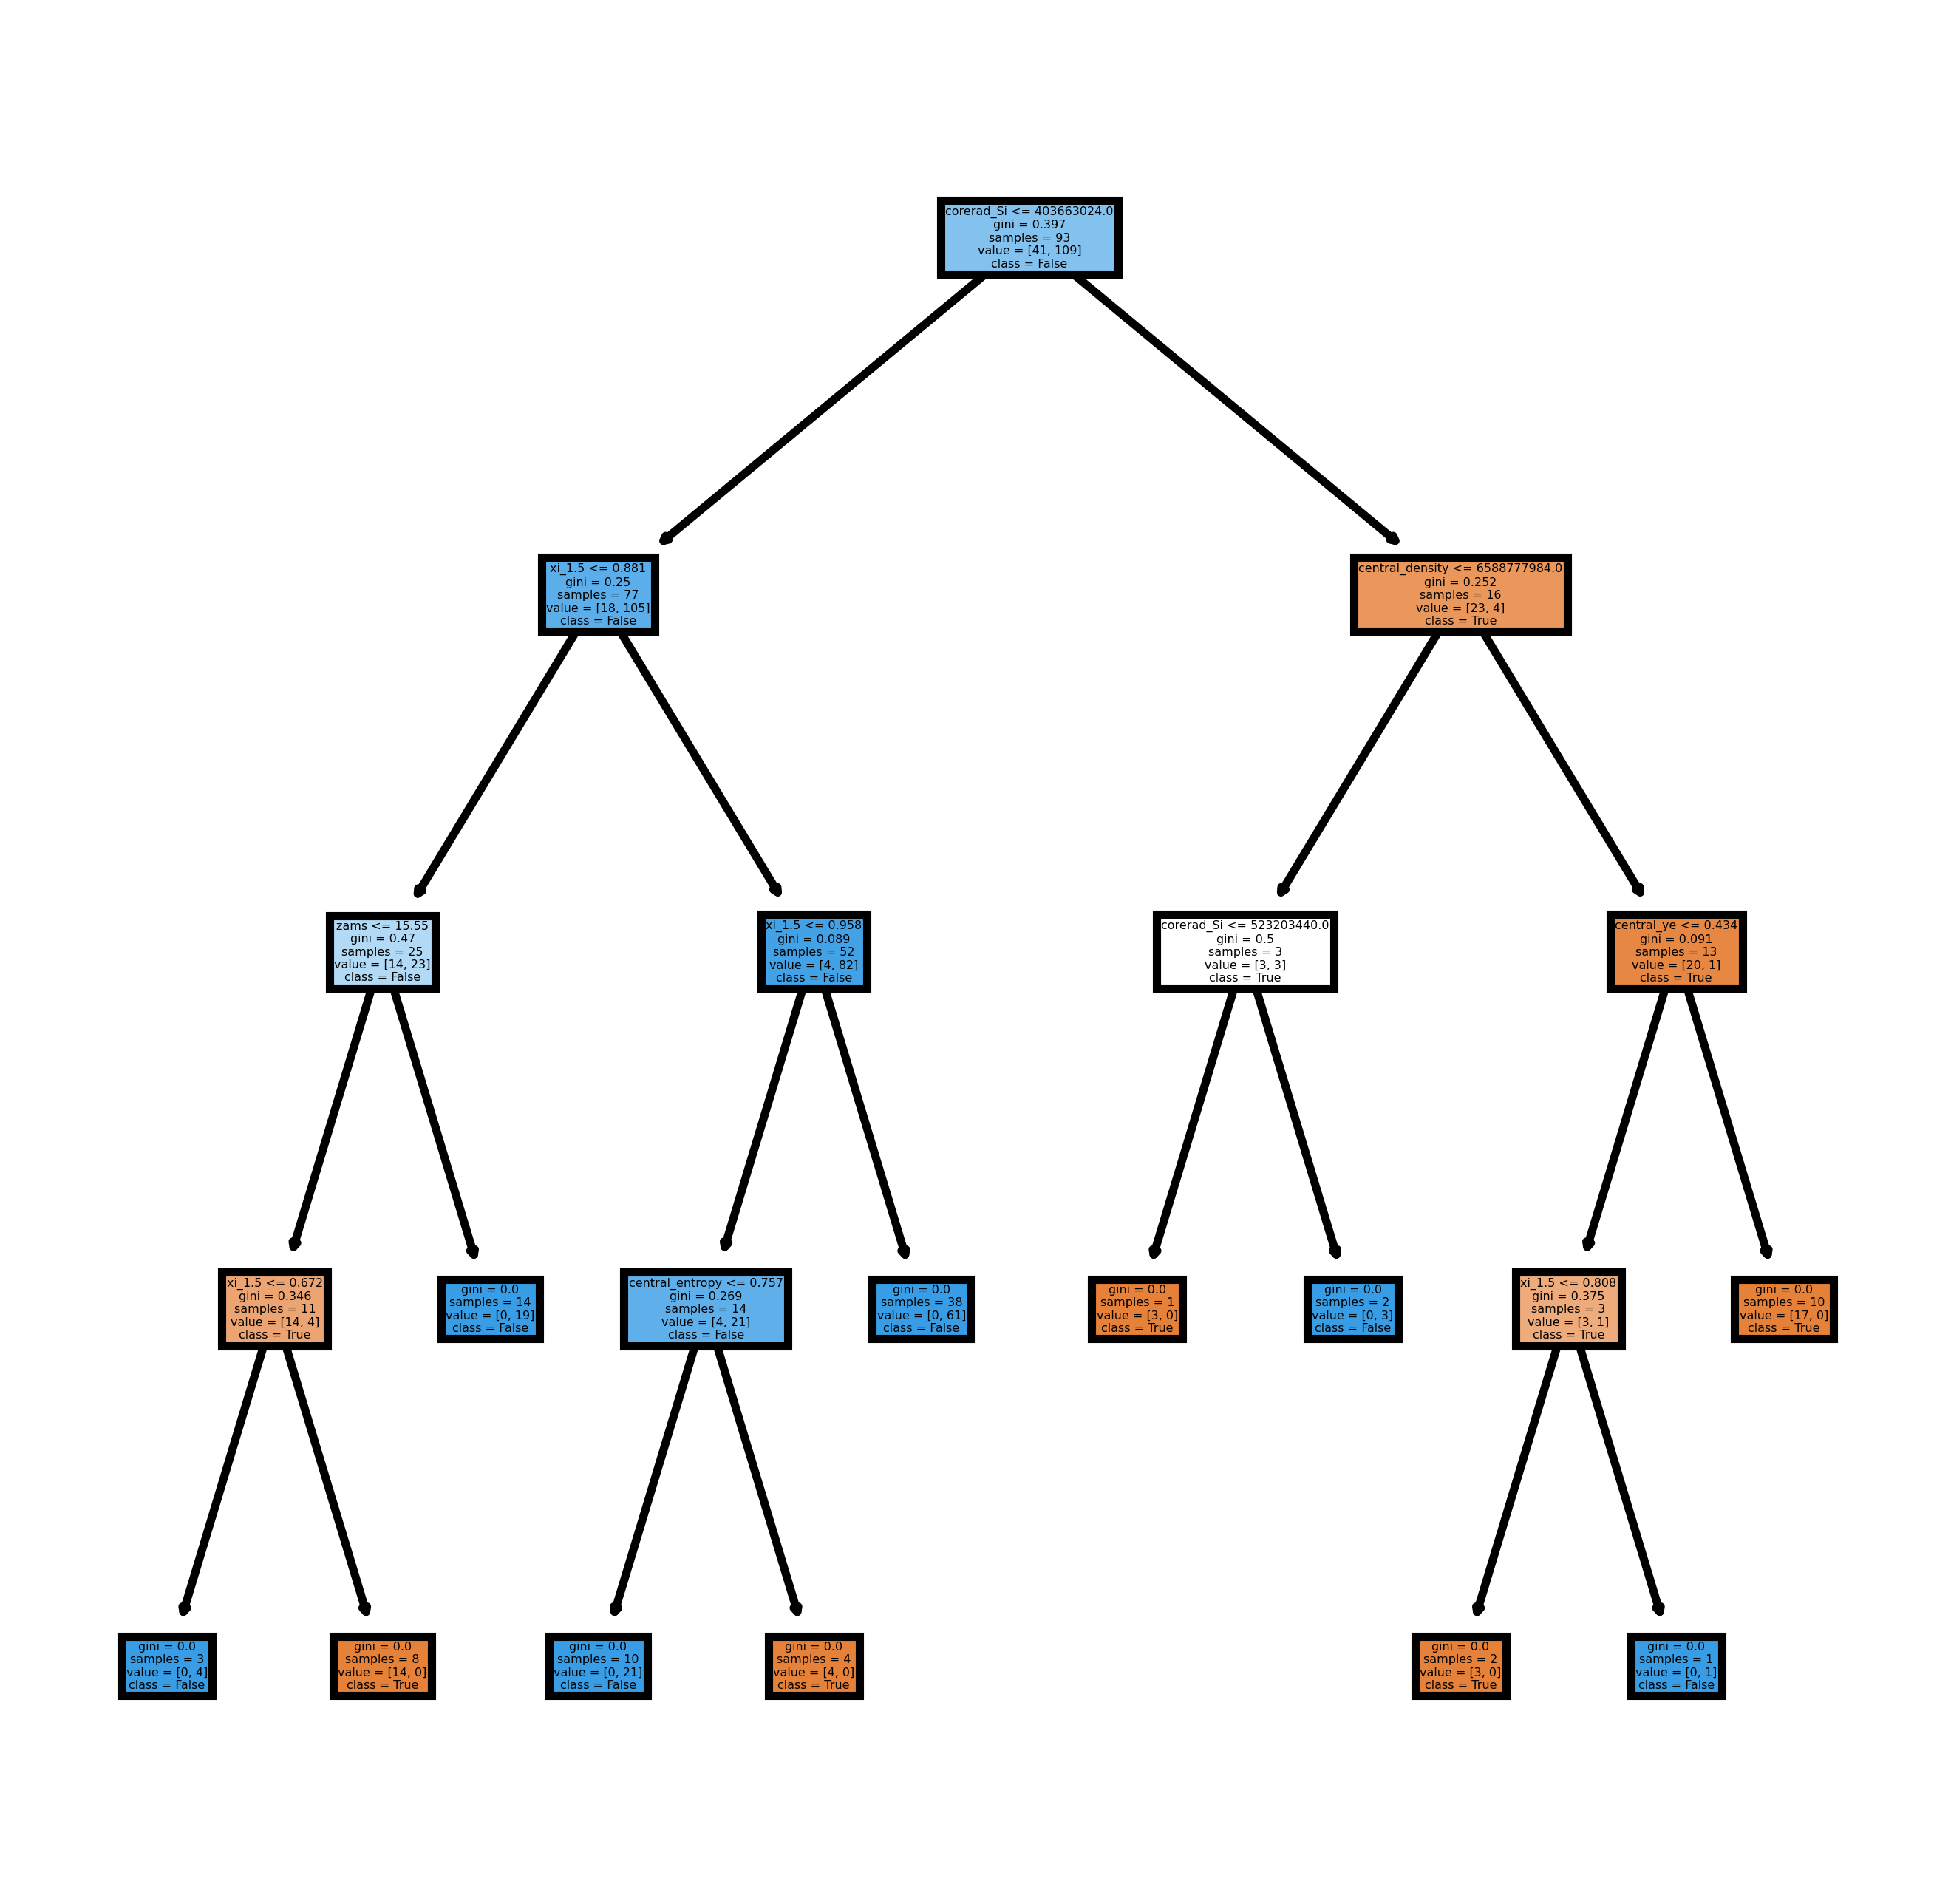

In [88]:
# extract one bootstrapped tree
fn=list(X.columns)
cn=['True', 'False']
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (4,4), dpi=800)
tree.plot_tree(best_model.estimators_[1],
               feature_names = fn, 
               class_names=cn,
               filled = True);

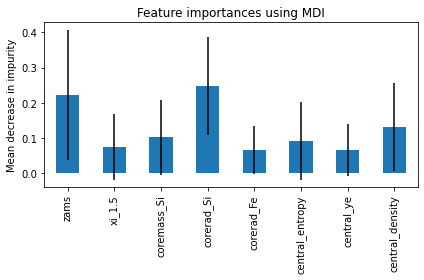

In [89]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [90]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 2.029 seconds


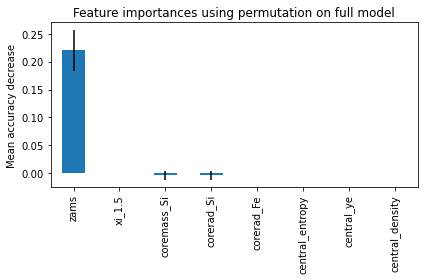

In [91]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

# DTC Without ZAMS

In [92]:
data = data.drop(['zams'], axis = 1)

In [93]:
# split data into train/test
X = data.drop(columns = ['exploded'])
y = data.exploded
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state = 304)

In [94]:
y_test.value_counts()/len(y_test)

True     0.76
False    0.24
Name: exploded, dtype: float64

In [95]:
y_train.value_counts()/len(y_train)

True     0.746667
False    0.253333
Name: exploded, dtype: float64

## DecisionTreeClassifier

In [96]:
# build decision tree
model = DecisionTreeClassifier(max_depth = 5, random_state = 304).fit(X_train, y_train)

In [97]:
# what tree was built?
print(tree.export_text(model, feature_names = list(X.columns)))

|--- corerad_Si <= 403663024.00
|   |--- xi_1.5 <= 0.96
|   |   |--- corerad_Fe <= 150787080.00
|   |   |   |--- corerad_Si <= 213086632.00
|   |   |   |   |--- class: True
|   |   |   |--- corerad_Si >  213086632.00
|   |   |   |   |--- corerad_Si <= 220787840.00
|   |   |   |   |   |--- class: False
|   |   |   |   |--- corerad_Si >  220787840.00
|   |   |   |   |   |--- class: True
|   |   |--- corerad_Fe >  150787080.00
|   |   |   |--- corerad_Si <= 209584992.00
|   |   |   |   |--- class: True
|   |   |   |--- corerad_Si >  209584992.00
|   |   |   |   |--- central_density <= 4778484736.00
|   |   |   |   |   |--- class: True
|   |   |   |   |--- central_density >  4778484736.00
|   |   |   |   |   |--- class: False
|   |--- xi_1.5 >  0.96
|   |   |--- class: True
|--- corerad_Si >  403663024.00
|   |--- xi_1.5 <= 0.81
|   |   |--- class: False
|   |--- xi_1.5 >  0.81
|   |   |--- corerad_Si <= 550800192.00
|   |   |   |--- class: False
|   |   |--- corerad_Si >  550800192.00
|  

In [98]:
# score produced
model.score(X_test, y_test)

0.92

In [99]:
# tune hyper parameters
max_depth = range(1,11)
fit_params = {'max_depth': max_depth}
model_cv = GridSearchCV(DecisionTreeClassifier(), fit_params, cv = 10, scoring = 'accuracy', n_jobs = -1)
model_cv.fit(X_train, y_train)
best_model = model_cv.best_estimator_

In [100]:
model_cv.best_params_

{'max_depth': 6}

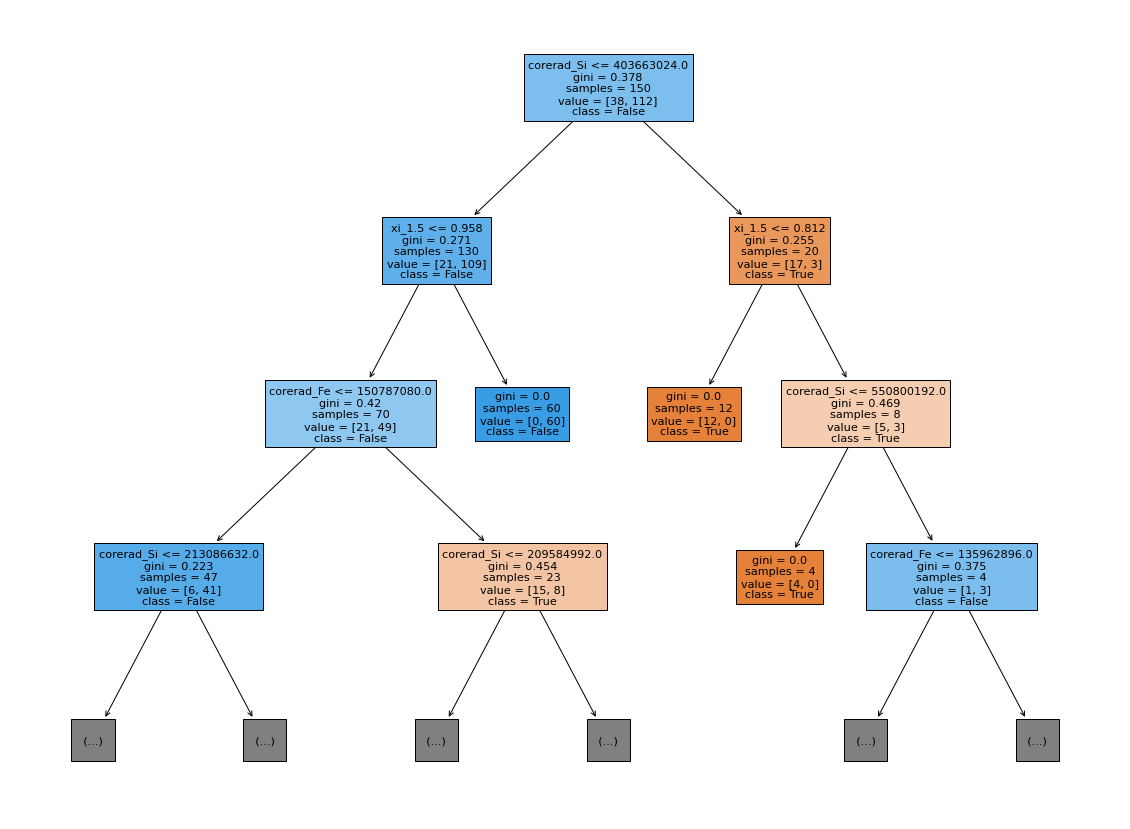

In [101]:
# visualize tree
plt.figure(figsize=(20,15))
tree.plot_tree(best_model,
              feature_names=list(X.columns),
              class_names=["True", "False"],
              filled = True,
              max_depth=3)
plt.show()

## RandomForestClassifier

In [102]:
# build model
model = RandomForestClassifier(random_state = 0, n_estimators = 50).fit(X_train, y_train)
model.score(X_test, y_test)

0.92

In [103]:
# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 500, 1000],  
    'max_features': ['sqrt', 'log2', None],
    'max_depth': [None, 3, 5, 10],
    'criterion': ['gini',] #'entropy']
}

# Create RandomForestClassifier
rf_model = RandomForestClassifier(random_state=6)

# Create GridSearchCV object
cv_model = GridSearchCV(rf_model, param_grid, scoring='accuracy', cv=10, n_jobs=-1)

# Fit the model on training data
cv_model.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=6), n_jobs=-1,
             param_grid={'criterion': ['gini'], 'max_depth': [None, 3, 5, 10],
                         'max_features': ['sqrt', 'log2', None],
                         'n_estimators': [100, 500, 1000]},
             scoring='accuracy')

In [104]:
best_model = cv_model.best_estimator_
print(best_model.score(X_test, y_test))
cv_model.best_params_

0.9


{'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'n_estimators': 100}

### Feature importance

for more information on plots:
<br>
https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

**Note:** Using Model that was NOT cross validated

In [105]:
import time

import numpy as np

feature_names = list(X.columns)
start_time = time.time()
importances = model.feature_importances_
std = np.std([tree.feature_importances_ for tree in model.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.032 seconds


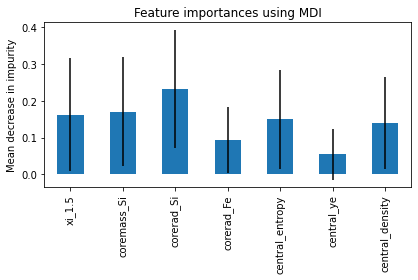

In [106]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)

fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [107]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    best_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=feature_names)

Elapsed time to compute the importances: 1.993 seconds


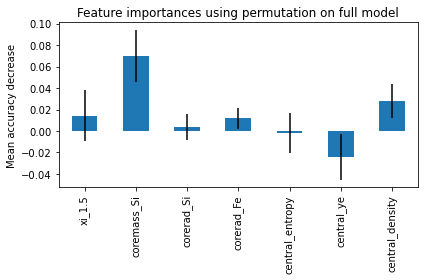

In [108]:
fig, ax = plt.subplots()
forest_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()